# CS 577 Phase 3 Group
**Group 17:** Anthony Alarcon (Member A) and Maeki Kashana (Member B)
**File:** `Group17_Anthony_Maeki_Phase3.ipynb`

This file is the group composite. Anthony's third is filled in: Part 0, figures A1-A4, the A4 upgrade, figure MA, and the Part 2C checklist. Cells marked **TODO Maeki** are her third. Part 3, Part 4, and Part 5 are left for the last third, after both portfolios are in.

# README

Files to submit with this notebook:

- `Group17_Anthony_Maeki_Phase3.ipynb`
- `Group17_Anthony_Maeki_Phase3.html`
- `phase2_working.csv`

Order: Kernel, Restart and Run All. The notebook loads `phase2_working.csv` from the same folder. No snapshot. No dataset switch.

Working dataset: `phase2_working.csv`, 6,528 rows by 9 columns, state-months from 2016-01 through 2026-08, 51 regions (50 states and D.C.). `YEAR` is added in code and is not a new file.


# Part 0: What Changed from Phase 2

1. **Was the research question modified?** No.

Phase 2 version, and the Phase 3 version, are the same sentence:

How has the housing market changed over the period of a decade across the fifty U.S. states and have these housing markets in these states remained relatively similar throughout this time frame, or have they experienced either a substantial growth or decline in their markets?

2. **Was the dataset modified?** No. We did not switch datasets, and we did not write a new working file. No instructor permission was needed.

3. **How?** Later cells load `phase2_working.csv` and print the shape before `YEAR` is added. That print is 6,528 by 10, which is the Phase 2 lock after Guam, Puerto Rico, and the U.S. Virgin Islands were dropped. `YEAR` is derived from `PERIOD BEGIN` for the slot 1 and slot 3 plots. It is not saved back over the working file. Phase 4 should keep using `phase2_working.csv`.

4. **Why?** A1 shows the file is balanced: 612 state-months in each finished year, and 408 in 2026 only because the download stops in August. That is a cutoff, not a missing-market problem, so the decade comparison still holds if 2026 is labeled as a partial year. A2 shows homes sold are right-skewed (skew 2.31) but the minimum is 480, so the Phase 2 territory drop already removed the empty rows. A3 shows the state-median price distribution shifting up every year, from about $200,000 in 2016 to about 375,000 in 2026, which is the growth the question asks about. The question still says fifty states. The file has 51 regions because D.C. is in it. We are keeping D.C. rather than dropping it, and we will name it when we talk about states.


In [91]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_rows', 20)

df = pd.read_csv('phase2_working.csv', parse_dates=['PERIOD BEGIN', 'PERIOD END'])
print('shape', df.shape)
print('date range', df['PERIOD BEGIN'].min().date(), 'to', df['PERIOD BEGIN'].max().date())
print('regions', df['REGION NAME'].nunique())

df['YEAR'] = df['PERIOD BEGIN'].dt.year
print('shape after YEAR', df.shape)
print(df.dtypes)


shape (6528, 8)
date range 2016-01-01 to 2026-08-01
regions 51
shape after YEAR (6528, 9)
PERIOD BEGIN         datetime64[ns]
PERIOD END           datetime64[ns]
REGION NAME                  object
HOMES SOLD                  float64
MEDIAN_SALE_PRICE           float64
MEDIAN_DOM                  float64
NEW LISTINGS                float64
ACTIVE LISTINGS             float64
YEAR                          int32
dtype: object


# Part 1: Composite Portfolio

## 1A. Combine

A1 to A4 are copied from Anthony's individual notebook, with the question, the read, and the principle check. B1 to B4 are not in this file yet.

**TODO Maeki:** paste B1 to B4 here, each with the markdown above and below the plot, then fill the B rows in the coverage table.


## A1. Year counts

**Question.** Did every year in the cleaned file get the same number of state-months, or is the end of the window thinner than the start? That matters for the research question because a short 2026 would make a decade comparison unfair if I treated 2026 like a full year.

**Variables.** `YEAR` (qualitative, ordinal). Built from `PERIOD BEGIN` so the bar is a category count, not a time series.

**Why this chart.** Slot 1 wants a bar of counts. A line would pretend year is a continuous axis and hide that 2026 is just fewer rows. Counts are the point here.


YEAR
2016    612
2017    612
2018    612
2019    612
2020    612
2021    612
2022    612
2023    612
2024    612
2025    612
2026    408
Name: count, dtype: int64


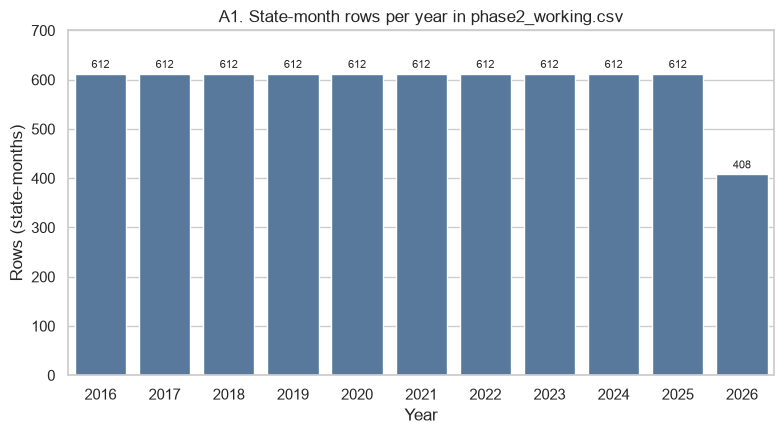

In [92]:
# A1
year_counts = df['YEAR'].value_counts().sort_index()
print(year_counts)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=year_counts.index.astype(str), y=year_counts.values, color='#4C78A8', ax=ax)
ax.set_title('A1. State-month rows per year in phase2_working.csv')
ax.set_xlabel('Year')
ax.set_ylabel('Rows (state-months)')
ax.set_ylim(0, 700)
for i, v in enumerate(year_counts.values):
    ax.text(i, v + 12, str(v), ha='center', fontsize=8)
fig.tight_layout()
plt.show()


**What it shows.** 2016 through 2025 each have 612 rows. That is 51 regions times 12 months. 2026 has 408 rows, which is 51 times 8 months (January through August). Nothing is missing inside a finished year. The file is balanced until the last partial year.

**What it does not show.** It does not say anything about prices or sales. A year with 612 rows can still be a weird market.

**Principle check.** Context. I labeled the y-axis as rows, not "activity," and I started the y-axis at 0 so 2026 does not look like the market collapsed. The short bar is a cutoff in the download, not a crash.


## A2. Homes sold

**Question.** Are monthly home sales spread pretty evenly across states, or do a few big states own the right tail? The research question asks if markets look similar. Volume is one way they do not.

**Variables.** `HOMES SOLD` (quantitative, discrete). Counts of homes sold in that state-month.

**Why this chart.** Slot 2. A histogram shows the shape better than a rug plot, which would just be a smear at this row count. I expected a long right tail, so a KDE alone would hide how piled up the small states are.


count     6528.0
mean      6856.5
std       7304.2
min        480.0
25%       1761.2
50%       4617.0
75%       9508.5
max      48549.0
Name: HOMES SOLD, dtype: float64
skew: 2.31
share under 5,000: 0.517
share under 10,000: 0.767


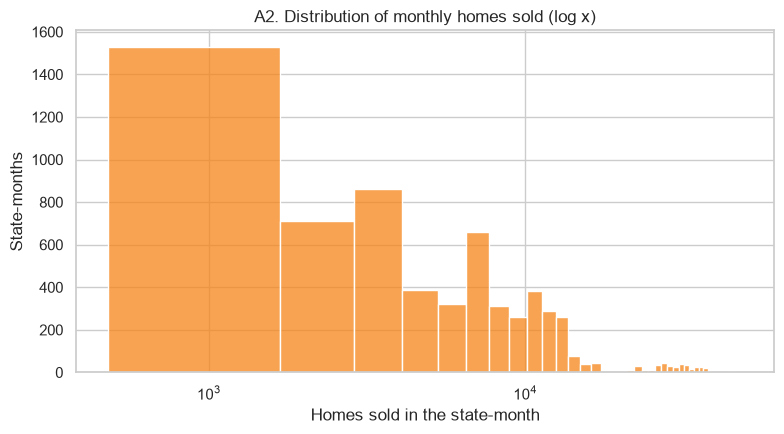

In [93]:
# A2
print(df['HOMES SOLD'].describe().round(1))
print('skew:', round(df['HOMES SOLD'].skew(), 2))
print('share under 5,000:', round((df['HOMES SOLD'] < 5000).mean(), 3))
print('share under 10,000:', round((df['HOMES SOLD'] < 10000).mean(), 3))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df['HOMES SOLD'], bins=40, color='#F58518', ax=ax)
ax.set_title('A2. Distribution of monthly homes sold (log x)')
ax.set_xlabel('Homes sold in the state-month')
ax.set_ylabel('State-months')
ax.set_xscale('log')
fig.tight_layout()
plt.show()


**What it shows.** The distribution is right skewed (skew about 2.3). Median is 4,617 homes, mean is about 6,856, max is 48,549. A little over half the rows are under 5,000, and about 77% are under 10,000. The long tail is the big states (California, Texas, Florida), not a data error. Min is 480, so there are no zero-sale months left after the Phase 2 territory drop.

**What it does not show.** A log axis compresses the big states, so it is easy to forget Florida can sell around 30k homes in a month while Wyoming sits under 1,000.

**Principle check.** Scale. On a linear x-axis most of the mass sat in the first couple bars. I switched the x-axis to log so the small-state pile and the big-state tail are both readable.


## A3. Sale price across years

**Question.** Did the typical state median sale price climb across the decade, or did states stay in the same band? This is the growth-or-not half of the research question.

**Variables.** `MEDIAN_SALE_PRICE` (quantitative, continuous, USD) across `YEAR` (qualitative, ordinal).

**Why this chart.** Slot 3. A box plot shows the middle and the spread for each year. Overlaid KDEs for 11 years would be a mess. A violin would show the same shift with more ink than I need.


        median      mean
YEAR                    
2016  200000.0  221699.0
2017  214200.0  233597.0
2018  224975.0  246650.0
2019  235000.0  259120.0
2020  258500.0  283236.0
2021  299950.0  325371.0
2022  334375.0  358065.0
2023  348250.0  365774.0
2024  360000.0  386287.0
2025  370000.0  397853.0
2026  375000.0  406179.0


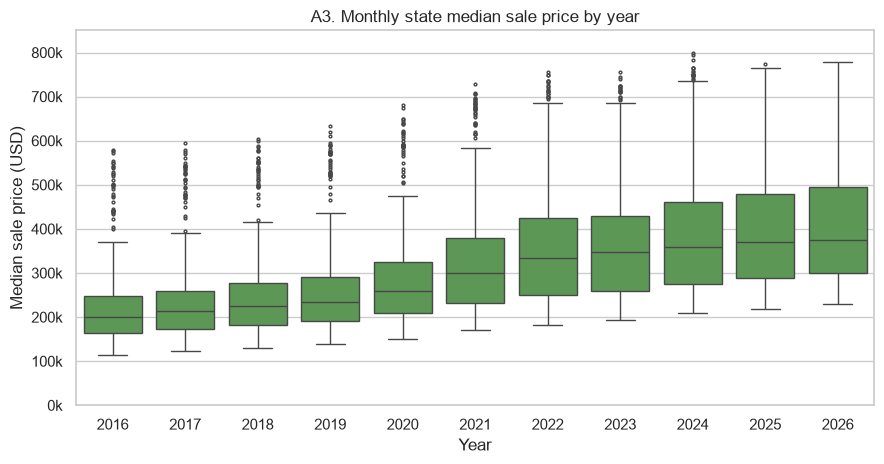

In [94]:
# A3
year_price = df.groupby('YEAR')['MEDIAN_SALE_PRICE'].agg(['median', 'mean']).round(0)
print(year_price)

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(
    data=df, x='YEAR', y='MEDIAN_SALE_PRICE',
    color='#54A24B', ax=ax, fliersize=2
)
ax.set_title('A3. Monthly state median sale price by year')
ax.set_xlabel('Year')
ax.set_ylabel('Median sale price (USD)')
ax.set_ylim(0, 850000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
fig.tight_layout()
plt.show()


**What it shows.** The box shifts up every year. Median of the state medians goes from about 200,000 in 2016 to about 334,000 in 2022 and about 375,000 in 2026 (2026 is only Jan-Aug). The jump is steeper from 2020 to 2022 than from 2016 to 2019. The boxes also sit higher without getting wildly wider, so states moved up together more than they split apart. Hawaii, D.C., and California stay in the top whisker the whole time. Highest single state-month in the file is 800,000.

**What it does not show.** A box plot hides which state is which. It also averages over seasons inside the year, so a spring bump and a winter dip get stacked in the same box.

**Principle check.** Scale. I kept the y-axis starting at 0. Starting near $200k would make the 2016-2019 climb look like a collapse-and-recovery. Context also: 2026 is an 8-month year, so that last box is not a full year.


## A4. Price vs days on market

**Question.** Do more expensive state-months also sit longer, or is price mostly separate from how fast homes move? If price and speed move together, growth in the research question is not just a dollar number.

**Variables.** `MEDIAN_SALE_PRICE` (quantitative, continuous, USD) and `MEDIAN_DOM` (quantitative, discrete, days).

**Why this chart.** Slot 4. A scatter is the direct comparison. Hex would hide the thin high-price band. I used alpha because 6,528 points pile up in the middle.


corr price vs days on market: -0.352


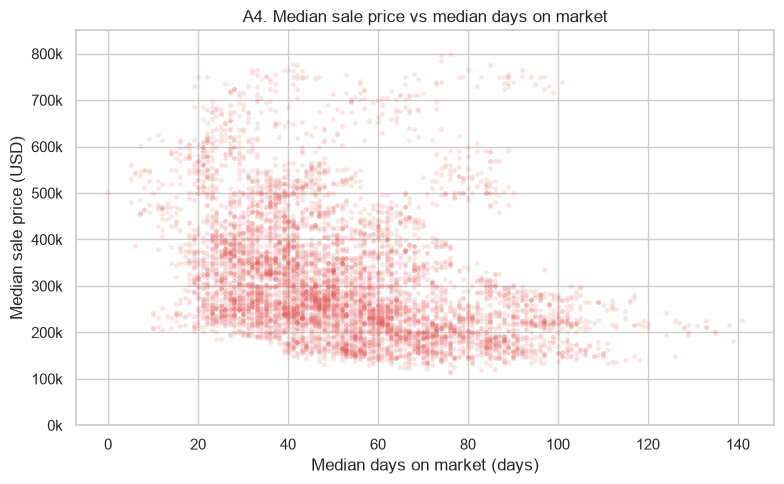

In [95]:
# A4
print('corr price vs days on market:', round(df['MEDIAN_SALE_PRICE'].corr(df['MEDIAN_DOM']), 3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    df['MEDIAN_DOM'], df['MEDIAN_SALE_PRICE'],
    alpha=0.15, s=12, c='#E45756', linewidths=0
)
ax.set_title('A4. Median sale price vs median days on market')
ax.set_xlabel('Median days on market (days)')
ax.set_ylabel('Median sale price (USD)')
ax.set_ylim(0, 850000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
fig.tight_layout()
plt.show()


**What it shows.** Correlation is about -0.35. Higher price state-months tend to have fewer days on market, but the cloud is wide. Plenty of $200k months sit at 30 days and plenty sit at 80. The expensive band (Hawaii, D.C., California, mostly above $500k) is not the slow band. Days on market in this file run from 0 to 141, with a mean around 52. Price runs from $115,000 to $800,000.

**What it does not show.** One point is a whole state-month, so a -0.35 correlation is not "a house sells faster because it is expensive." Population and year are both sitting under this cloud.

**Principle check.** Perception. Points pile up between about 30 and 70 days, so I set alpha to 0.15. A solid scatter would look like one blob and invent a tighter relationship than there is.


## B1: REGION NAME Bar Plot

**The Question**

* How many times, across a decade, has a state's median housing sale price became more than 600,000 and which state(s) had instances of the median sale price reaching that amount?
    * This connects to the research question because this bar chart is only displaying the states that had, at certain times, a median of over 600,000 across 10 years and it also shows the amount of times that the states median price has gone over that amount. One can conclude that, during those times, there is a higher buyer demand of houses which is the reason the median sale price increased.
    
**The variables and their types**
* Y-Axis - `Instances of Median Above $600,000` $\to$ (Quantitative, Discrete)
* X-Axis - `REGION NAME` $\to$ (Qualitative, Nominal)

**Why this chart**
* The reason why I chose this chart is because it was the best option to represent the counts of the qualitative variable `REGION NAME` after filtering the dataset with a specific condition using the `MEDIAN_SALE_PRICE` variable. 


REGION NAME                           object
Instances of Median Above $600,000     int64
dtype: object



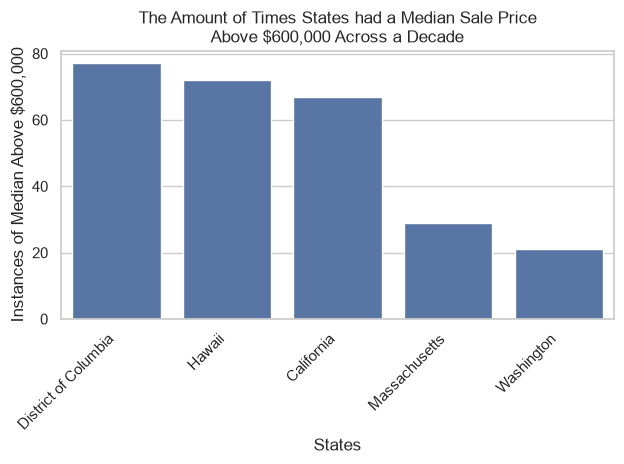

In [96]:
median_price = df[df['MEDIAN_SALE_PRICE'] > 600000]
counts = median_price[["REGION NAME"]].value_counts().reset_index(name='Instances of Median Above $600,000')
counts 
print(f'{counts.dtypes}\n')

sns.barplot(data=counts, x='REGION NAME', y='Instances of Median Above $600,000')
plt.title("The Amount of Times States had a Median Sale Price\n Above $600,000 Across a Decade ")
plt.xlabel("States")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**What it shows**

* This bar chart shows the names of the states that had a median housing sale price of over $600,000. Furthermore, this chart also shows the frequency, across 10 years, that the states had their median in this range. This chart also shows that, out of more than 6000 rows, the maximum amount of instances (rows) where a certain state had their median sale price in this range is around 78.

**What it does not show**

* This chart does not show the specific times in which a certain state's median sale price was in this range.

**Principle check**

* The principle that I checked is context. To be more specific, the title of the chart makes it so that the plot is easily understood to a stranger. The title helps explain the x and y axis better. Because of this principle, I made sure the title gave an accurate explanation of the axis and the data shown in the chart.

## B2: MEDIAN_DOM Histogram

**The Question**

* How long have most homes in the United States stayed on the market for in the last decade?
    * This connects to the research question because this histogram shows how long most homes stay on the market for, while also showing the least and most amount of days that homes have stayed on the market for in a period of 10 years. One can use this data to find out how many days, across 10 years, that most homes in the U.S. have stayed on the market for.
    
**The variables and their types**
* Y-Axis - The density of homes that stayed on the market for a specific number of days $\to$ (Quantitative, Discrete)
* X-Axis - `MEDIAN_DOM` $\to$ (Quantitative, Discrete)

**Why this chart**
* The reason why I chose a kde plot over a histogram is because, after testing out the histogram, there were slight fluctuations in the data which created noise that might distract the viewer from seeing the 'story' that the plot is tyring to convey. A kde plot makes it easier to make conclusions based off the plot since it clearly shows the distribution of median days on market. I did not choose the rugplot because there was overplotting which made it diffuclt to discern the distribution.

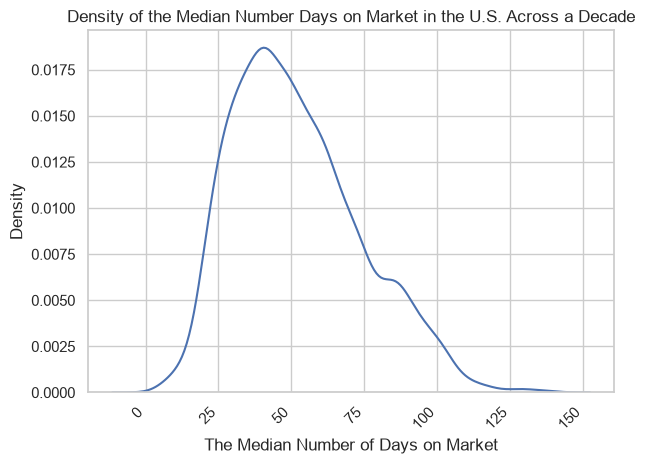

In [97]:
median_dom = df

sns.kdeplot(data=median_dom, x='MEDIAN_DOM')

plt.title("Density of the Median Number Days on Market in the U.S. Across a Decade")
plt.ylabel("Density")
plt.xlabel("The Median Number of Days on Market")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**What it shows**

* This kde plot shows the distribution of the median number of days on market for each state across 10 years for home listings. Furthermore, for each number of days on market, the kde plot shows the density of the amount of homes that fall within that number of days. From looking at the plot, it can be seen that most homes typically spend less than 50 days on market across all US states. Furthermore, a right skew can also be observed as the median number of days on market increases after the point of highest density.

**What it does not show**

* This plot does does show the specific states when showing the density of states that have a median days on market.

**Principle check**

* The principle that I checked is context. In this principle, I had first used a histogram to display the distribution but there were bars in the histogram that created noise and made it more difficult for a stranger to discern what the plot is trying to convey. By switching to a kde plot, the reader would have an easier time inferring conclusions from looking at the chart without the confusion caused by the noise in the histogram.

## B3: sale price by state Side-by-side violin plots

**The Question**

* Which states have had a median sale price above 750,000 across the time frame of 10 years?
    * This connects to the research question because these side by side violin plots show the states that had a median sale price that is above 93% of the max median sale price, which is $800,000, across all states. From this data, one can infer the states that had the best and most expensive housing market across the ten year period. The states with the most expensive median sale price show that the demand for housing in these states is high.
    
**The variables and their types**
* Y-Axis - `MEDIAN_SALE_PRICE` above 750K $\to$ (Quantitative, continuous)
* X-Axis - `REGION NAME` $\to$ (Qualitative, Nominal)

**Why this chart**
* The reason why I chose side by side violin plots over overlaid histograms, kde plots, or box plots is because the violin plots accurately show the density for each median price above 750K. To explain further, the plot makes it evident that some median price values have more than one state that has that median price. On the other hand, histplots, kde's, and box blots fail to accurately show the density of states that have a certain median price and, despite the fact that histplots do show the density, the resulting graph is not readable or comprehensible, particularly to a stranger. The reason why I did not choose kde plots is because they do not show the states that have a certain density in some values.

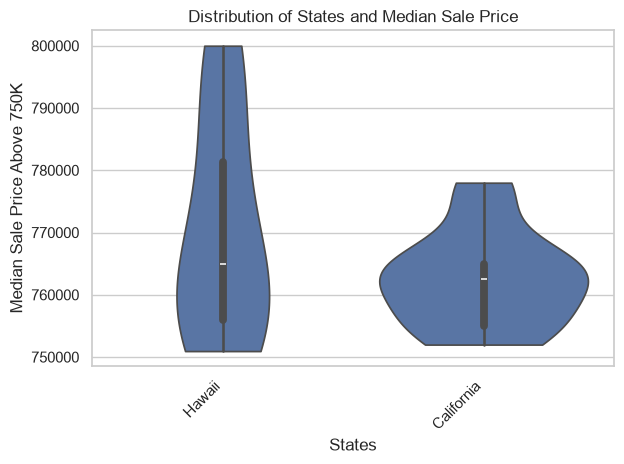

In [98]:
median_price = df[df["MEDIAN_SALE_PRICE"] > 750000]

sns.violinplot(data=median_price, x='REGION NAME',y="MEDIAN_SALE_PRICE", cut=0)

plt.title("Distribution of States and Median Sale Price")
plt.ylabel("Median Sale Price Above 750K")
plt.xlabel("States")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**What it shows**

* These violin plots show the states that have a median sale price of over 750K across the ten year time frame. By looking at the graph, it is apparent that there are various instances of a singular state reaching a specific median sale price, while other median sale prices only have one instance of a state having that value. As can be seen on the graph, California and Hawaii are the only two states that have median sale prices in this range. Furthermoore, California has most of its data points in the 760-770K range while Hawaii is more evenly spread out from around 755-800K.

**What it does not show**

* These violin plots do not show, similar to previous plots, the actual dates in which the states had a certain median sale price value.

**Principle check**

* The principle that I checked is scale. To be more specific, when creating the graph for the first time, I noticed that the violin graph stretched further than 800K and less than 750K, despite the fact that these values are not covered in the data. Because of this, it makes it seem to a stranger that there are data points at these values, despite the fact that this is not the case. To fix this issue, I included the `cut=0` option to the violin plot code which made it so that the plot cuts off at the max and min values.

## B4: `HOMES SOLD` vs `NEW LISTINGS` Scatter Plot

**The Question**

* What is the relationship between the amount of homes sold and the amount of new home listings?
    * This connects to the research question because it shows the relationship between median sale price and the number of new listings, which is a predominant factor in determining a good housing market, according to https://www.housingwire.com/articles/how-to-read-local-housing-market-trends/.
    
**The variables and their types**
* Y-Axis - `NEW HOME LISTINGS` $\to$ (Quantitative, discrete)
* X-Axis - `NUMBER OF HOMES SOLD` $\to$ (Quantitative, discrete)

**Why this chart**
* The reason why I chose a scatter plot with a fitted line is because this plot most accurately and clearly shows the relationship between new home listings and homes solds. With a hex plot or contour plot, the relationship isn't as obvious for the regular viewer. Although the scatter plot without the fitted line also shows the same relationship, the fitted line works to make it more obvious that there is a linear relationship.

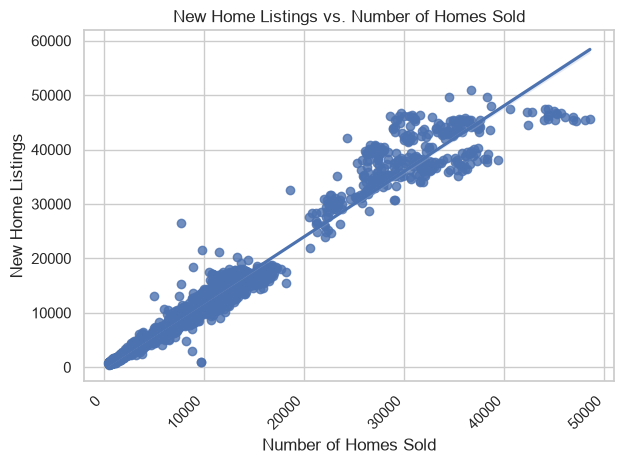

In [99]:
sales_listings = df

sns.regplot(data=sales_listings, x='HOMES SOLD',y="NEW LISTINGS")

plt.title("New Home Listings vs. Number of Homes Sold")
plt.ylabel("New Home Listings")
plt.xlabel("Number of Homes Sold")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**What it shows**

* This fitted scatterplot shows the relationship between the number of homes sold and the number of listings across a ten-year time frame. As shown in the plot, there is a linear relationship between these two variables. To explicate, while there are a few outliers, as the number of homes sold increases, the number of new home listings also increases. However, the relationship seems to 'flatten' between 40000 and 50000 homes sold (it stops being linear).

**What it does not show**

* These scatterplots do not show the states that sold the specific amount of homes and they also do not show the specific year in which these number of homes were sold.

**Principle check**

* The principle that I checked is conditioning. I switched to a scatterplot with a fitted line because I wanted the linear relationship between new home listings and number of homes sold to be as obvious as possible and easy to see.

**TODO Maeki:** paste B1 to B4 above this table, then replace the B rows.

| Figure | Member | Slot | Variables | Question it answers | Principle checked |
|---|---|---|---|---|---|
| A1 | Anthony | 1 | `YEAR` | Is 2026 a full year of rows, or a short download? | Context: y-axis is rows and starts at 0 |
| A2 | Anthony | 2 | `HOMES SOLD` | Are sales volumes similar across states, or is there a big-state tail? | Scale: log x so the small-state pile is visible |
| A3 | Anthony | 3 | `MEDIAN_SALE_PRICE` by `YEAR` | Did the typical state median climb, or stay in one band? | Scale: y-axis starts at 0 |
| A4 | Anthony | 4 | `MEDIAN_SALE_PRICE` vs `MEDIAN_DOM` | Do higher prices sit with faster sales? | Perception: alpha 0.15 so the pile does not look solid |
| B1 | Maeki | 1 | `REGION NAME` | How many times, across a decade, has a state's median housing sale price became more than 600,000 and which state(s) had instances of the median sale price reaching that amount? | Context $\to$ made the title so that it accurately describes what the plot is showing. |
| B2 | Maeki | 2 | `MEDIAN_DOM` | How long have most homes in the United States stayed on the market for in the last decade? | Context $\to$ first used histogram, but created too much noise. Switched to kde plot to accurately show what the data is trying to convey. |
| B3 | Maeki | 3 | `MEDIAN_SALE_PRICE` by `REGION NAME` | Which states have had a median sale price above 750,000 across the time frame of 10 years? | Scale $\to$ the stretch of the violin plots above max and min were cut off to make it less confusing to reader |
| B4 | Maeki | 4 | `HOMES SOLD` vs `NEW LISTINGS` | What is the relationship between the amount of homes sold and the amount of new home listings? | Conditioning $\to$ added fitted line to scatterplot to plainly show the comparison. |



Anthony's four, read together: the file is balanced enough to compare years (A1), states are not the same size (A2), the typical state median rose every year and the boxes did not blow apart (A3), and price is only loosely tied to days on market (A4). A3 is the plot that answers the growth half of the question. A2 is the plot that answers the "remained similar" half, and it says no on volume. A4 does not contradict A3. A slow month is not the same thing as a cheap year. The synthesis of all eight has to wait until B1 to B4 are in. B3 is the one most likely to disagree with A3, because a national year box can rise while a few states do not.

B1-B4 Read Together: The data in these plots show that there is a linear relationship between the number of homes sold, the new home listings, and the active home listings. To explicate, as the number of homes sold increases, then the number of listings (for both active and new) increases. In addition, the plots also show that the median amount of time that a home has stayed on the market actoss a 10-year period is less than 50 days. Furthermore, the other plots show that, interestingly, the states whose median sale prices go above \$600,000 are Democratic 'blue' states. 



## 1B. Upgrade the two weakest

Anthony's pick for his half: A4 is the weaker of his four. It checks perception, but it fails conditioning. One cloud mixes 2016 and 2026, so the downward line looks like a price-speed law when part of it is a year shift.


Maeki's pick for the second weakest plot: "Density of the Median Number Days on Market in the U.S. Across a Decade". This plot checks context, but fails conditioning. It is better to split the median number of days on market by year so that years where the market was not as good (not enough buyers) would not affect years where the market was good. This will allow readers to see, across specific years, how long most houses stay on the market before being sold.


#### First Weak Plot

**Why A4 is weak.** A4 fails conditioning: the points are not split by year, so a reader cannot see whether the negative slope is the same relationship in every year.


corr price vs days on market: -0.352


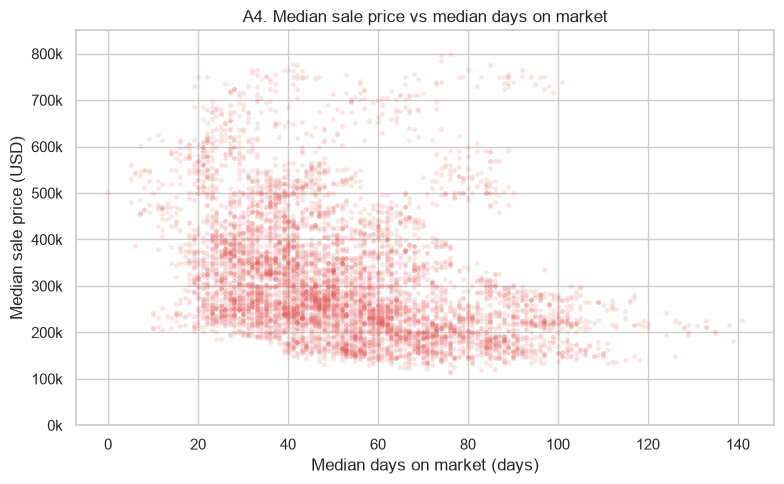

In [100]:
# Original A4 Code

# A4
print('corr price vs days on market:', round(df['MEDIAN_SALE_PRICE'].corr(df['MEDIAN_DOM']), 3))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    df['MEDIAN_DOM'], df['MEDIAN_SALE_PRICE'],
    alpha=0.15, s=12, c='#E45756', linewidths=0
)
ax.set_title('A4. Median sale price vs median days on market')
ax.set_xlabel('Median days on market (days)')
ax.set_ylabel('Median sale price (USD)')
ax.set_ylim(0, 850000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
fig.tight_layout()
plt.show()

corr within year:
YEAR
2016   -0.399
2017   -0.405
2018   -0.375
2019   -0.291
2020   -0.284
2021   -0.277
2022   -0.106
2023    0.055
2024    0.041
2025    0.110
2026    0.091
dtype: float64


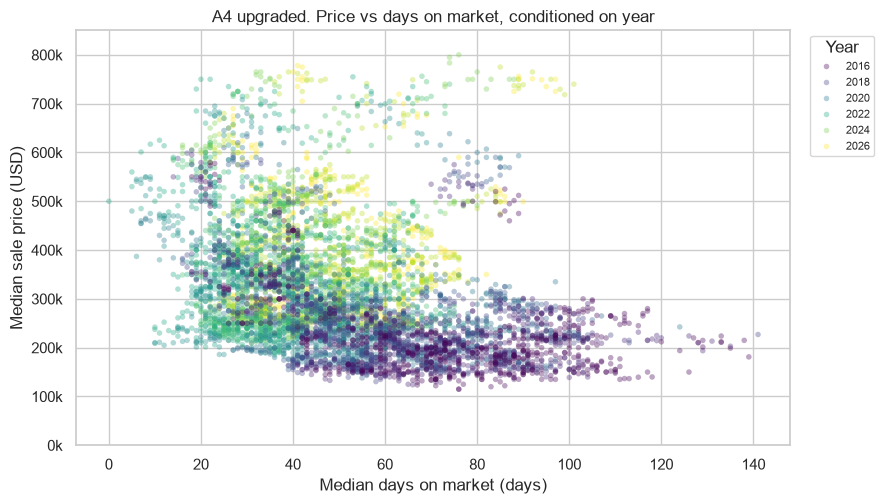

In [101]:
# A4 upgrade: same columns, conditioned on year

print('corr within year:')
print(df.groupby('YEAR').apply(
    lambda g: g['MEDIAN_SALE_PRICE'].corr(g['MEDIAN_DOM']),
    include_groups=False
).round(3))

fig, ax = plt.subplots(figsize=(9, 5.2))
sns.scatterplot(
    data=df, x='MEDIAN_DOM', y='MEDIAN_SALE_PRICE',
    hue='YEAR', palette='viridis', alpha=0.35, s=16,
    linewidth=0, ax=ax
)
ax.set_title('A4 upgraded. Price vs days on market, conditioned on year')
ax.set_xlabel('Median days on market (days)')
ax.set_ylabel('Median sale price (USD)')
ax.set_ylim(0, 850000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
ax.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
fig.tight_layout()
plt.show()


**What the upgrade shows.** The cheap, slow cloud is mostly the early years, and the expensive cloud is mostly 2021-2026. The negative slope in the original is partly a year mix, not a single price-speed law. Within a year the correlation is weaker than the pooled -0.35.


#### Second Weak Plot

**Why B2 is weak.** B4 fails conditioning $\to$ years where the market was not as good (not enough buyers) would  affect years where the market was good, thereby making the denisty of the median number of days on market not as accurate.


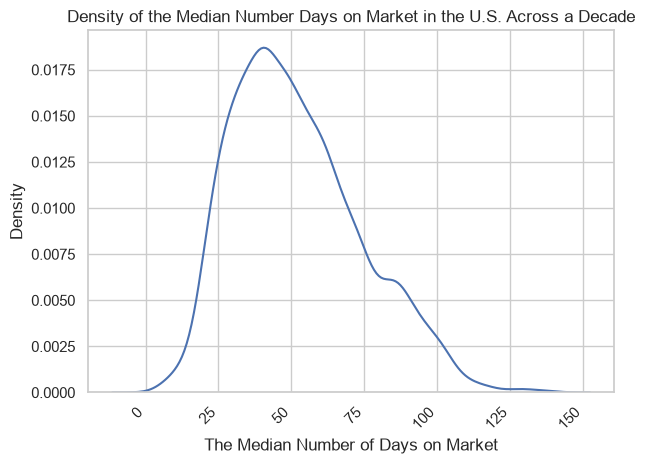

In [102]:
# Original B2 Plot code

median_dom = df

sns.kdeplot(data=median_dom, x='MEDIAN_DOM')

plt.title("Density of the Median Number Days on Market in the U.S. Across a Decade")
plt.ylabel("Density")
plt.xlabel("The Median Number of Days on Market")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

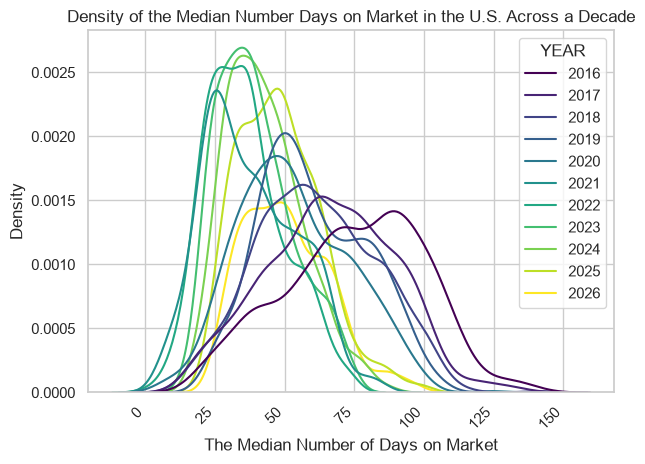

In [103]:
# Upgraded B2 Plot Code

median_dom = df

sns.kdeplot(data=median_dom, x='MEDIAN_DOM',hue='YEAR',palette='viridis')

plt.title("Density of the Median Number Days on Market in the U.S. Across a Decade")
plt.ylabel("Density")
plt.xlabel("The Median Number of Days on Market")

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**What the upgrade shows.** 

* The upgrade reveals the median number of days on market for specific years that the original had hid. In this plot, it is more clear to see that in the later years, houses spend less time on the market compared to the earlier years.


# Part 2: Lie Detector

## 2A. The swap

**TODO Maeki:** before you read the 2C under MA, write your detection in a markdown cell titled with your name. Anthony will do the same for MB once that plot is in this notebook. Do not fill those cells from the 2C below.


### Anthony Alarcon

1. Whether you believed the headline at first glance, honestly.
2. Which principle you think was broken, and the specific design choice you think does the
damage.
3. What you would change to fix it.

4. Is the guess correct?

### Maeki Kashana


1. Whether you believed the headline at first glance, honestly.
    * At first, upon seeing the graph, I did not see anything wrong with it and therefore I believed it.
2. Which principle you think was broken, and the specific design choice you think does the
damage.
    * Upon examining the plot, the principle I think is broken is scale, primarily because there seems to be a drastic disparity between the first and last bin.  The specific design choice that does the damage is the removal of certain points in the y-axis which made it so that the bins appear smaller than they really are compared to other bins.
3. What you would change to fix it.
    * In order to fix it, I would make it so the y-values start from 0 to the max sale price instead of starting from 200K.

4. Is the guess correct?
    * My guess is essentially correct because it was mentioned that the limits of the y-axis were changed and the scale was broken.

## 2B. Both plots, fixed

MA is below, with the required label, the false headline, the honest rebuild, and the 2C. Principle broken: scale.

**TODO Maeki:** paste MB under MA. Her principle has to be different. The split was context or perception.

### MA (Anthony Alarcon)

**MISLEADING ON PURPOSE**

False headline: Typical state home prices more than doubled after 2016, and the later years are in a different league from the start of the file.

Principle broken on purpose: scale. Same rows and same column as the honest plot (`YEAR`, `MEDIAN_SALE_PRICE`). No values were edited.


YEAR
2016    221699.0
2017    233597.0
2018    246650.0
2019    259120.0
2020    283236.0
2021    325371.0
2022    358065.0
2023    365774.0
2024    386287.0
2025    397853.0
2026    406179.0
Name: MEDIAN_SALE_PRICE, dtype: float64
2016 mean 221699
2026 mean 406179
ratio 2026/2016 1.832


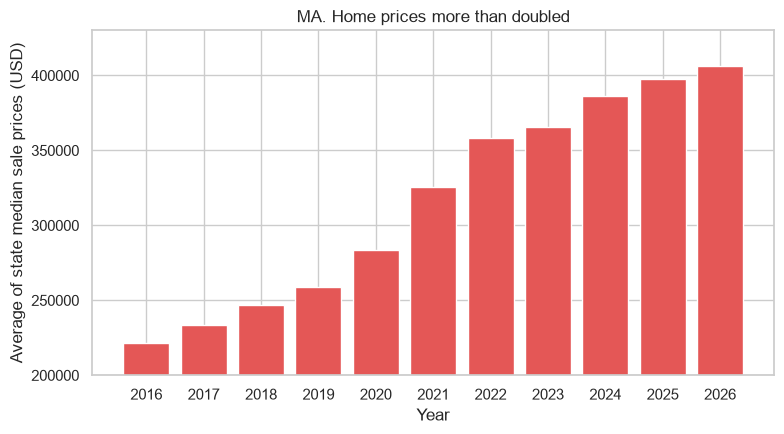

In [104]:
# MA misleading: yearly mean of state median sale price, y-axis chopped
yearly = df.groupby('YEAR')['MEDIAN_SALE_PRICE'].mean()
print(yearly.round(0))
print('2016 mean', round(yearly.loc[2016]))
print('2026 mean', round(yearly.loc[2026]))
print('ratio 2026/2016', round(yearly.loc[2026] / yearly.loc[2016], 3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(yearly.index.astype(str), yearly.values, color='#E45756')
ax.set_ylim(200000, 430000)  # scale trick: chop off the baseline
ax.set_title('MA. Home prices more than doubled')
ax.set_xlabel('Year')
ax.set_ylabel('Average of state median sale prices (USD)')
fig.tight_layout()
plt.show()


## Honest rebuild of MA

Same yearly means, same years, y-axis starts at 0, title does not claim a doubling.


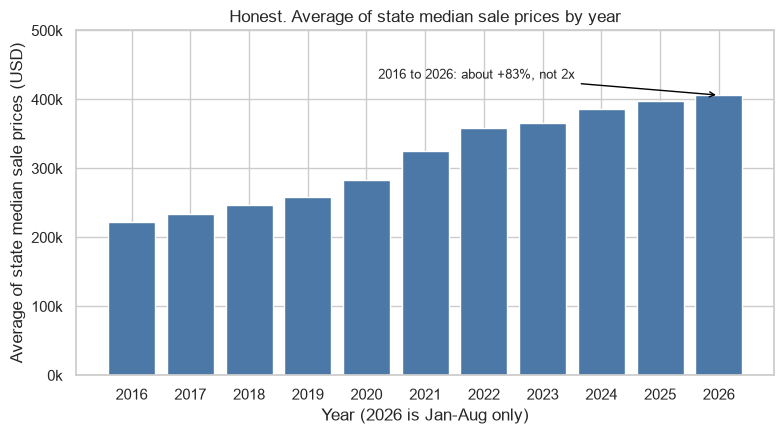

In [105]:
# honest version of MA
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(yearly.index.astype(str), yearly.values, color='#4C78A8')
ax.set_ylim(0, 500000)
ax.set_title('Honest. Average of state median sale prices by year')
ax.set_xlabel('Year (2026 is Jan-Aug only)')
ax.set_ylabel('Average of state median sale prices (USD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
ax.annotate(
    '2016 to 2026: about +83%, not 2x',
    xy=(10, yearly.loc[2026]),
    xytext=(4.2, 430000),
    fontsize=9,
    arrowprops=dict(arrowstyle='->', color='black')
)
fig.tight_layout()
plt.show()


## 2C for MA

I broke scale. The damage is `ax.set_ylim(200000, 430000)` on the misleading bar chart, plus a title that says prices more than doubled. The bars are yearly means of `MEDIAN_SALE_PRICE`, about 222k in 2016 and about 406k in 2026. That is roughly 1.83 times, not more than double. Chopping the axis makes the 2016 bar look like a stub and the 2026 bar look like it fills the chart, so a reader treats the climb as a different order of magnitude. The honest plot uses the same means and starts at 0. The climb is real, especially 2020 to 2022, but the false headline does not survive. 2026 is also only eight months, which the misleading title does not say.


### MB (Maeki Kashana)

#### MISLEADING ON PURPOSE

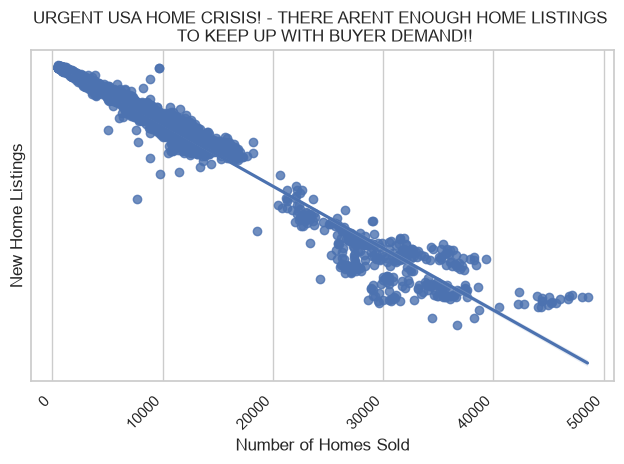

In [106]:
sales_listings = df

sns.regplot(data=sales_listings, x='HOMES SOLD',y="NEW LISTINGS")

plt.title("URGENT USA HOME CRISIS! - THERE ARENT ENOUGH HOME LISTINGS \n TO KEEP UP WITH BUYER DEMAND!!")
plt.ylabel("New Home Listings")
plt.xlabel("Number of Homes Sold")

plt.gca().invert_yaxis()

plt.xticks(rotation=45, ha='right')
plt.yticks([])
plt.tight_layout()
plt.show()

#### The Honest Plot

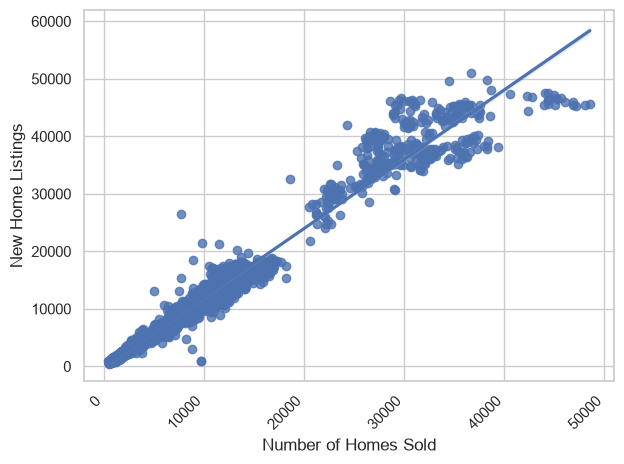

In [107]:
sales_listings = df

sns.regplot(data=sales_listings, x='HOMES SOLD',y="NEW LISTINGS")

#plt.title("URGENT USA HOME CRISIS! - THERE ARENT ENOUGH HOME LISTINGS \n TO KEEP UP WITH BUYER DEMAND")
plt.ylabel("New Home Listings")
plt.xlabel("Number of Homes Sold")

#plt.gca().invert_yaxis()

plt.xticks(rotation=45, ha='right')
#plt.yticks([])
plt.tight_layout()
plt.show()

#### 2C. How the Trick Works

1. Name the principle you broke.

    * The principle that I broke is the 'context' principle. I did so by inverting the y-axis and removing its values to make the y-axis appear to be decreasing when, in fact, it is decreasing.
2. Point to the exact code choice that does the damage (for example, ax.set_ylim(95, 100)or cmap="jet").

    * The first line that caused the damage is `plt.gca().invert_yaxis()` because it is what allowed the y-axis to be inverted so that it looks like it is decreasing.
    * The second line that caused the damage is `plt.yticks([])` because it removed the y values from the axis to make the reader think that the y-axis is decreasing when it is actually increasing.
3. Explain why a reader’s eye falls for it.
    * The reader's eye falls for it because, without any prior knowledge about the data and how it was plotted, the reader would think that the number of new home listings is going down as the number of homes being sold in going up, which allows one to conclude there isn't enough supply to meet the demand.
4. State what the honest plot shows instead, and whether the false headline survives at all.
    * Unlike the misleading plot, the honest plot shows the real relationship between the number of homes sold and the number of new home listings, which is that the number of new home listings increases as the number of homes sold increases. If the false headline were to be applied to the honest graph, then it would not be possible for that headline to survive because the honest graph clearly shows an increasing linear relationhip between the two variables instead of an decreasing one like it it shown in the misleading graph.

## 2C. The checklist

Run this on every plot in Phase 4 and in the final report. A check counts only if someone can answer it by looking at the figure.

- **Scale.** Does every bar chart start its y-axis at 0? If an axis is truncated or logged, does the title or the axis label say so?
- **Conditioning.** If two groups should be compared, are they in the same panel, and is the fair measure a rate rather than a raw count?
- **Perception.** Are we asking the reader to compare lengths, not area or angle? If color encodes a number, is the palette one sequence, not a rainbow?
- **Context.** Does a stranger get the units, the sample size or row count, the source file, and a title that does not claim more than the axes show?

Scale was the easy one to catch on MA, because a bar that does not start at 0 is a visible cut. The harder catch in a swap is usually context: a leading title can be true-sounding while the axis is fine. We will know which one was hardest once MB has been read cold.


# Part 3: Hero figure

**TODO, last third.** One plot that answers the research question, a four-row principle table, and a caption with the finding, units, source, and row count. A3 is the current candidate. Do not build it until B3 is in, so the hero is not only the year view.


### Part 2C Checklist Check

| Checklist | How the meets the plot requirements |
|----------|----------|
| **Scale.** Does every bar chart start its y-axis at 0? If an axis is truncated or logged, does the title or the axis label say so?    |      The plot has its y-axis starting at 0; it is not truncated    |
| **Conditioning.** If two groups should be compared, are they in the same panel, and is the fair measure a rate rather than a raw count?    |     Boxplots of median sale prices of different years are being compared in the same panel     |
| **Perception.** Are we asking the reader to compare lengths, not area or angle? If color encodes a number, is the palette one sequence, not a rainbow?    |     The reader is being asked to compare box plots showing the lower and upper quartiles, the median, and the outliers of median sale prices of housing across the United States in different years     |
| **Context.** Does a stranger get the units, the sample size or row count, the source file, and a title that does not claim more than the axes show?    |  The title of the plot does not claim more than what is shown by the axis. Furthermore, the units are straight forward and a reader could easily interpret them and the data shown in the plot        |

#### Figure`

        median      mean
YEAR                    
2016  200000.0  221699.0
2017  214200.0  233597.0
2018  224975.0  246650.0
2019  235000.0  259120.0
2020  258500.0  283236.0
2021  299950.0  325371.0
2022  334375.0  358065.0
2023  348250.0  365774.0
2024  360000.0  386287.0
2025  370000.0  397853.0
2026  375000.0  406179.0
(11, 2)


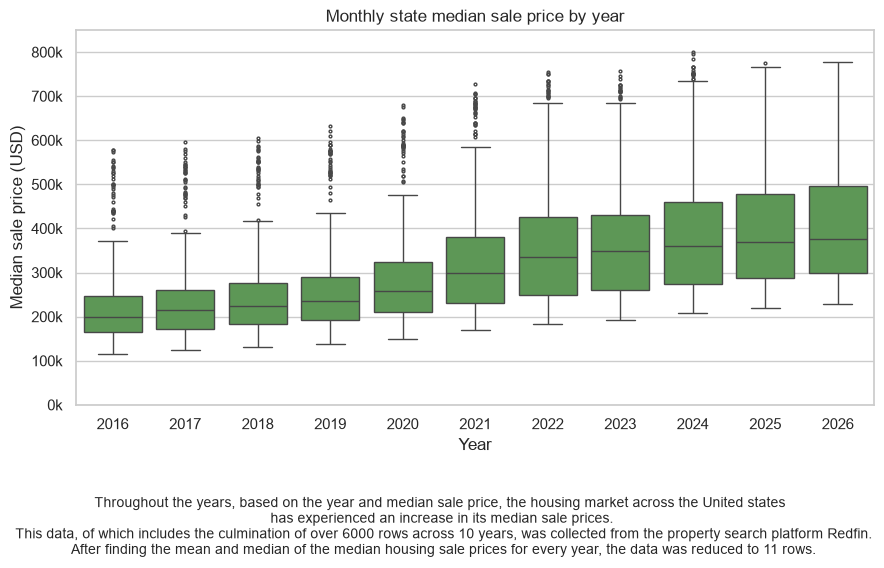

In [108]:
year_price = df.groupby('YEAR')['MEDIAN_SALE_PRICE'].agg(['median', 'mean']).round(0)
print(year_price)

print(f'{year_price.shape}')

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(
    data=df, x='YEAR', y='MEDIAN_SALE_PRICE',
    color='#54A24B', ax=ax, fliersize=2
)
ax.set_title('Monthly state median sale price by year')
ax.set_xlabel('Year')
ax.set_ylabel('Median sale price (USD)')
ax.set_ylim(0, 850000)

# caption
fig.text(0.5, -0.05,
         "Throughout the years, based on the year and median sale price, the housing market across the United states \n\
has experienced an increase in \
its median sale prices.\n This data, of which includes the culmination of over 6000 rows across 10 years, was collected from the property search platform Redfin.\
\n After finding the mean and median of the median housing sale prices for every year, the data was reduced to 11 rows.",

         ha="center", va="top", fontsize=10, wrap=True)


ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
fig.tight_layout()
plt.show()

# Part 4: Model case

**TODO, last third.** Needs both individual target reads. Anthony's individual read: target `MEDIAN_SALE_PRICE`, regression, lean linear with year in it, baseline mean about $313,916. Maeki's read is not in this file yet. Do not write 4E until both reads are pasted.


## 4A. Target and Task 

##### Maeki Kashana

**Target Column**

*
    * `HOMES SOLD`
    
**Classification**

*
    * Quantitative (Discrete), regression



##### Anthony Alarcon

**Target Column**

*
    * `MEDIAN_SALE_PRICE`
    
**Classification**

*
    * Quantitative (Continuous), regression.  
    
  
 
  
The team is going with the MEDIAN_SALE_PRICE as the target variable because it is the best variable to answer the research question. To be more specific, this target variable would be the best determinant of the growth of the housing market across the US.

## 4B. Shape Evidence

### Plot 1 

Part 3: Hero Figure $\to$ "Monthly state median sale price by year"

#### Signal From Step 3

The signal can be best described as being a **linear model** because the ordering of the boxplots show a linear relationship between the Year and the median sale price. It shows that, year after year, the housing median sale price increases.

### Plot 2 

A4 Upgrade - "Price vs days on market, conditioned on year"

#### Signal From Step 3

This plot has signals for a linear model. While it is not a tight band, the plot does show a negative linear relationship between a target and a feature. More specifically, it shows that, for homes that remain for a long time on the market, the lower their sale price would be.

### Plot 3

#### Signal From Step 3

## 4C. Linear or Forest

| Question | What our plots show (cite figures) | Points toward |
|----------|-------------------------------------|---------------|
| Is the relationship roughly straight, or can a transformation make it so? | ... | Linear or forest |
| Are there thresholds, steps, or plateaus? | ... | ... |
| Do conditioned lines stay parallel or cross? | ... | ... |
| Do we need to explain each feature's effect in a sentence? | ... | ... |

## 4D. Leakage and Baseline 

## 4E. The Case

# Part 5: Honest data story

**TODO, last third.** 250 to 400 words, at least three figure labels including the hero, and one thing the data cannot tell us. Handout says this cell has to be our own words, so it stays empty here.


# Part 6: Contributions and AI use

**Anthony.** 

    * Brought A1-A4, MA, the honest rebuild, and the MA 2C over from the individual notebook. 
    * Wrote the Part 0 revisit from those plots, the coverage-table rows for A, the A4 upgrade, and the four-principle checklist.

**Maeki.** 

    * Moved over the required content from the individual assignment.
    * Completed Part 3: Hero Figure
    * Finished Upgrade of B2 Plot
    * 

**AI use.** Grok was used to assemble this group notebook from the individual notebook and the group handout, and for the seaborn hue syntax on the A4 upgrade. The housing CSV was not pasted in. The false headline and the MA 2C are the same text as the individual notebook. Part 2A, Part 4E, and Part 5 are not written yet.
